In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore

In [3]:
# CARREGAMENTO DOS DADOS
df = sns.load_dataset('diamonds')

print(df.head())


   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75


In [10]:
# ESTATÍSTICAS DESCRITIVAS E VALORES IMPOSSÍVEIS

print(df.describe())

# x, y e z são as dimensões dos diamantes
# Verificando se existem valores iguais a zero
print("\nValores iguais a zero:")

print("x:", (df['x'] == 0).sum())
print("y:", (df['y'] == 0).sum())
print("z:", (df['z'] == 0).sum())

              carat         depth         table         price             x  \
count  53940.000000  53940.000000  53940.000000  53940.000000  53940.000000   
mean       0.797940     61.749405     57.457184   3932.799722      5.731157   
std        0.474011      1.432621      2.234491   3989.439738      1.121761   
min        0.200000     43.000000     43.000000    326.000000      0.000000   
25%        0.400000     61.000000     56.000000    950.000000      4.710000   
50%        0.700000     61.800000     57.000000   2401.000000      5.700000   
75%        1.040000     62.500000     59.000000   5324.250000      6.540000   
max        5.010000     79.000000     95.000000  18823.000000     10.740000   

                  y             z  
count  53940.000000  53940.000000  
mean       5.734526      3.538734  
std        1.142135      0.705699  
min        0.000000      0.000000  
25%        4.720000      2.910000  
50%        5.710000      3.530000  
75%        6.540000      4.040000  


In [11]:
# DETECÇÃO — Z-SCORE

# Pegando apenas as colunas numéricas
numericas = df.select_dtypes(include='number').columns

print("\nOutliers pelo Z-score:")

for coluna in numericas:

    media = df[coluna].mean()
    desvio = df[coluna].std()

    z = (df[coluna] - media) / desvio

    outliers = (abs(z) > 3).sum()

    print(coluna, outliers)


Outliers pelo Z-score:
carat 439
depth 685
table 336
price 1206
x 43
y 34
z 55


In [12]:
# DETECÇÃO — IQR

print("\nOutliers pelo IQR:")

for coluna in numericas:

    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)

    iqr = q3 - q1

    minimo = q1 - 1.5 * iqr
    maximo = q3 + 1.5 * iqr

    outliers = (
        (df[coluna] < minimo) |
        (df[coluna] > maximo)
    ).sum()

    print(coluna, outliers)



Outliers pelo IQR:
carat 1889
depth 2545
table 605
price 3540
x 32
y 29
z 49


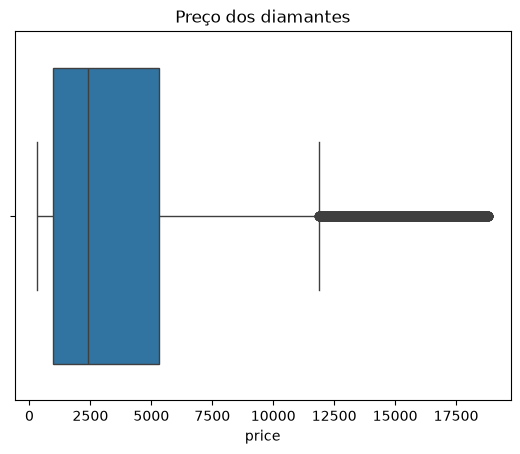

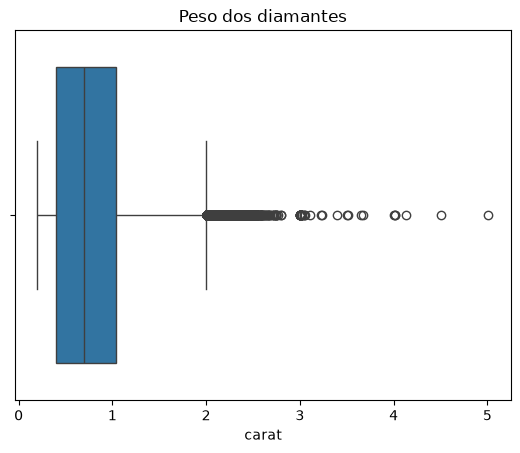

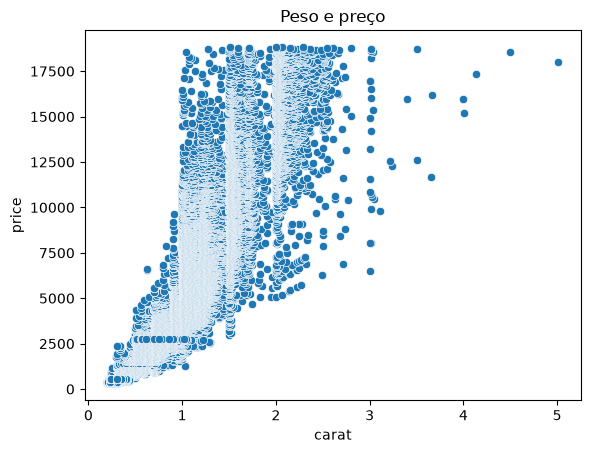

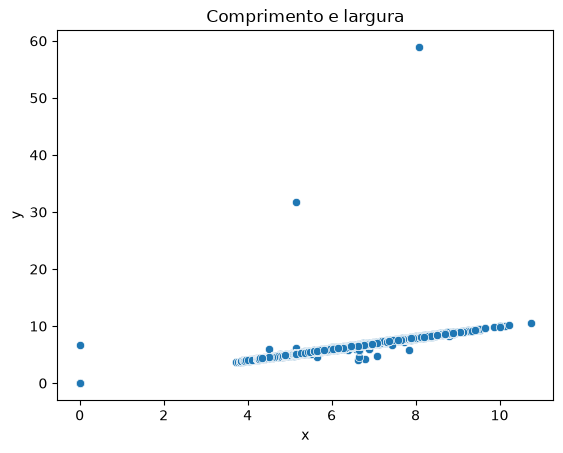

In [13]:
# VISUALIZAÇÕES

# Gráfico dos preços
sns.boxplot(x=df['price'])
plt.title('Preço dos diamantes')
plt.show()

# Gráfico dos pesos
sns.boxplot(x=df['carat'])
plt.title('Peso dos diamantes')
plt.show()

# Gráfico de peso e preço
sns.scatterplot(data=df, x='carat', y='price')
plt.title('Peso e preço')
plt.show()

# Gráfico das dimensões
sns.scatterplot(data=df, x='x', y='y')
plt.title('Comprimento e largura')
plt.show()



In [14]:
# ERRO x VALOR EXTREMO LEGÍTIMO

# Mostrando os diamantes com dimensão zero
erros = df[
    (df['x'] == 0) |
    (df['y'] == 0) |
    (df['z'] == 0)
]

print("\nRegistros com erros:")
print(erros)

# Mostrando os maiores preços
print("\nMaiores preços:")
print(df.nlargest(10, 'price'))




Registros com erros:
       carat        cut color clarity  depth  table  price     x     y    z
2207    1.00    Premium     G     SI2   59.1   59.0   3142  6.55  6.48  0.0
2314    1.01    Premium     H      I1   58.1   59.0   3167  6.66  6.60  0.0
4791    1.10    Premium     G     SI2   63.0   59.0   3696  6.50  6.47  0.0
5471    1.01    Premium     F     SI2   59.2   58.0   3837  6.50  6.47  0.0
10167   1.50       Good     G      I1   64.0   61.0   4731  7.15  7.04  0.0
11182   1.07      Ideal     F     SI2   61.6   56.0   4954  0.00  6.62  0.0
11963   1.00  Very Good     H     VS2   63.3   53.0   5139  0.00  0.00  0.0
13601   1.15      Ideal     G     VS2   59.2   56.0   5564  6.88  6.83  0.0
15951   1.14       Fair     G     VS1   57.5   67.0   6381  0.00  0.00  0.0
24394   2.18    Premium     H     SI2   59.4   61.0  12631  8.49  8.45  0.0
24520   1.56      Ideal     G     VS2   62.2   54.0  12800  0.00  0.00  0.0
26123   2.25    Premium     I     SI1   61.3   58.0  15397  8.52  

In [15]:
# TRATAMENTO — REMOÇÃO / CAPPING / TRANSFORMAÇÃO

# Removendo os registros com dimensões inválidas
df_base = df[
    (df['x'] > 0) &
    (df['y'] > 0) &
    (df['z'] > 0)
].copy()

# Calculando os limites do preço
q1 = df_base['price'].quantile(0.25)
q3 = df_base['price'].quantile(0.75)

iqr = q3 - q1

minimo = q1 - 1.5 * iqr
maximo = q3 + 1.5 * iqr


# REMOÇÃO

df_remocao = df_base.copy()

# Mantendo preços dentro dos limites
df_remocao = df_remocao[
    (df_remocao['price'] >= minimo) &
    (df_remocao['price'] <= maximo)
]

print("\nLinhas após remoção:")
print(len(df_remocao))


# CAPPING

df_capping = df_base.copy()

# Substituindo preços muito altos pelo limite
df_capping['price'] = df_capping['price'].clip(
    lower=minimo,
    upper=maximo
)

print("\nLinhas após capping:")
print(len(df_capping))


# TRANSFORMAÇÃO

df_log = df_base.copy()

# Aplicando logaritmo nos preços
df_log['price'] = np.log1p(df_log['price'])

print("\nLinhas após transformação:")
print(len(df_log))


Linhas após remoção:
50388

Linhas após capping:
53920

Linhas após transformação:
53920



Quantidade de linhas:
Original: 53940
Sem erros: 53920
Remoção: 50388
Capping: 53920
Transformação: 53920

Preço original:
count    53920.000000
mean      3930.993231
std       3987.280446
min        326.000000
25%        949.000000
50%       2401.000000
75%       5323.250000
max      18823.000000
Name: price, dtype: float64

Preço após remoção:
count    50388.000000
mean      3159.275462
std       2764.924572
min        326.000000
25%        911.000000
50%       2154.000000
75%       4668.250000
max      11883.000000
Name: price, dtype: float64

Preço após capping:
count    53920.000000
mean      3730.824694
std       3435.755287
min        326.000000
25%        949.000000
50%       2401.000000
75%       5323.250000
max      11884.625000
Name: price, dtype: float64

Preço após transformação:
count    53920.000000
mean         7.787048
std          1.014002
min          5.789960
25%          6.856462
50%          7.784057
75%          8.580027
max          9.842888
Name: price, dtype:

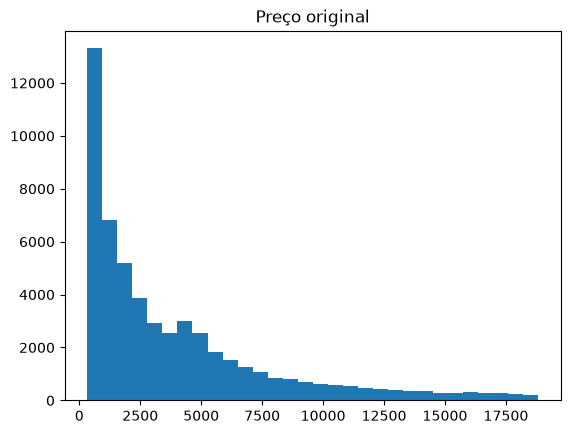

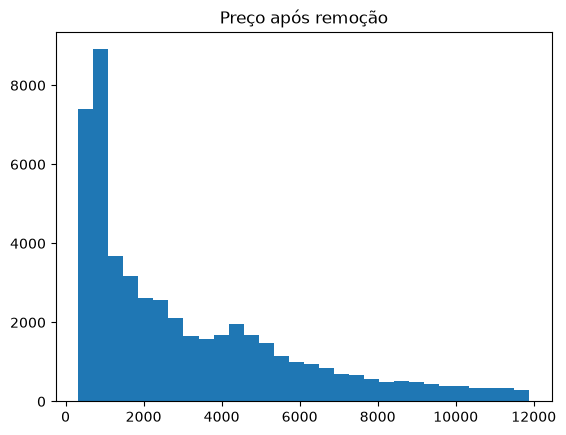

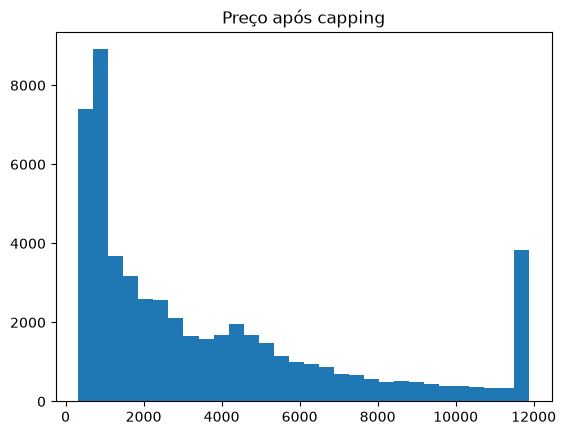

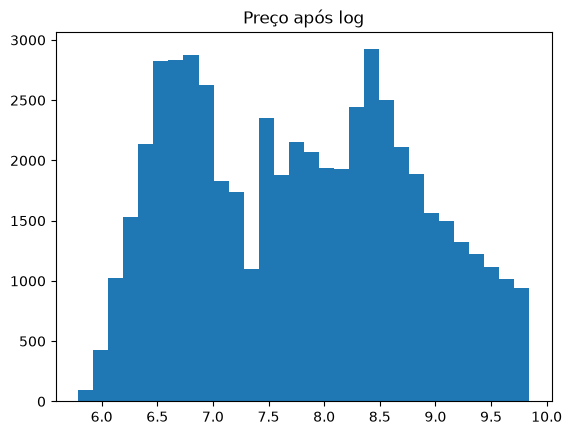

In [16]:
# COMPARAÇÃO ENTRE AS ESTRATÉGIAS

# Quantidade de registros
print("\nQuantidade de linhas:")

print("Original:", len(df))
print("Sem erros:", len(df_base))
print("Remoção:", len(df_remocao))
print("Capping:", len(df_capping))
print("Transformação:", len(df_log))


# Comparando as estatísticas
print("\nPreço original:")
print(df_base['price'].describe())

print("\nPreço após remoção:")
print(df_remocao['price'].describe())

print("\nPreço após capping:")
print(df_capping['price'].describe())

print("\nPreço após transformação:")
print(df_log['price'].describe())


# Gráfico do preço original
plt.hist(df_base['price'], bins=30)
plt.title('Preço original')
plt.show()

# Gráfico do preço após remoção
plt.hist(df_remocao['price'], bins=30)
plt.title('Preço após remoção')
plt.show()

# Gráfico do preço após capping
plt.hist(df_capping['price'], bins=30)
plt.title('Preço após capping')
plt.show()

# Gráfico do preço após transformação
plt.hist(df_log['price'], bins=30)
plt.title('Preço após log')
plt.show()

In [ ]:
# RESPOSTAS ÀS PERGUNTAS DE REFLEXÃO

# 1. O que significam x, y e z?
# São as medidas dos diamantes em milímetros.
# Valores iguais a zero são considerados inválidos.

# 2. Como foram encontrados os outliers?
# Foram usados os métodos Z-score e IQR.
# Os dois métodos podem mostrar quantidades diferentes.

# 3. Como foram visualizados?
# Foram usados boxplots e gráficos de dispersão.

# 4. Quais são erros e quais podem ser legítimos?
# Dimensões iguais a zero são erros de registro.
# Preços altos podem ser valores reais.

# 5. Quais tratamentos foram aplicados?
# Remoção, capping e transformação logarítmica.

# 6. Qual foi o impacto?
# A remoção diminuiu a quantidade de registros.
# O capping limitou os preços extremos.
# O log diminuiu as diferenças na escala dos preços.
